In [40]:
import h5py  # DAS usualy comes in HDF5 format
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
import pandas as pd
import obspy
import matplotlib
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 

wavelength = 1550 * 1e-9 # wavelength, 1550 nm
refractive_index = 1.4682
photoelastic_coefficient = 0.78

## Looking at data from this event: https://earthquake.usgs.gov/earthquakes/eventpage/ak0239lyp68s/executive

In [41]:
picks = pd.read_csv('20230728_M5_picks.csv')

In [42]:
picks

,channel,KKFLS_p_sec,KKFLS_s_sec,TERRA_p_sec,TERRA_s_sec,KKFLN_p_sec,KKFLN_s_sec
0,100,14.60,32.84,13.86,32.40,NaN,NaN
1,101,13.44,32.98,13.48,32.34,NaN,NaN
2,102,13.96,32.76,13.38,32.26,NaN,NaN
3,103,14.02,32.70,13.78,32.46,NaN,NaN
4,104,14.10,33.06,13.76,32.46,NaN,NaN
...,...,...,...,...,...,...,...
7495,7595,9.12,24.54,7.06,21.84,NaN,NaN
7496,7596,9.20,24.44,7.54,21.94,NaN,NaN
7497,7597,9.32,24.40,6.44,21.90,NaN,NaN
7498,7598,9.18,24.30,8.20,21.84,NaN,NaN


In [43]:
h5file = '20230728_M5_KKFLS.h5'

data = h5py.File(h5file)
kkfls_attrs=dict(data['Acquisition'].attrs)
kkfls_das = np.array(data['Acquisition/Raw[0]/RawData'])
kkfls_time = np.array(data['Acquisition/Raw[0]/RawDataTime'])
data.close()

dt = 1/kkfls_attrs['MaximumFrequency']/2
dx = kkfls_attrs['SpatialSamplingInterval']
nt,nx = kkfls_das.shape

kkfls_x = np.linspace(0,nx*dx,nx) # This is in meters
kkfls_x_km = kkfls_x / 1000
kkfls_t = np.linspace(0,nt*dt,nt)


gl = kkfls_attrs['GaugeLength']
correction_factor = wavelength / (photoelastic_coefficient * 4 * np.pi * refractive_index * gl) # correction factor for strain rate
kkfls_corrected_das = kkfls_das * correction_factor

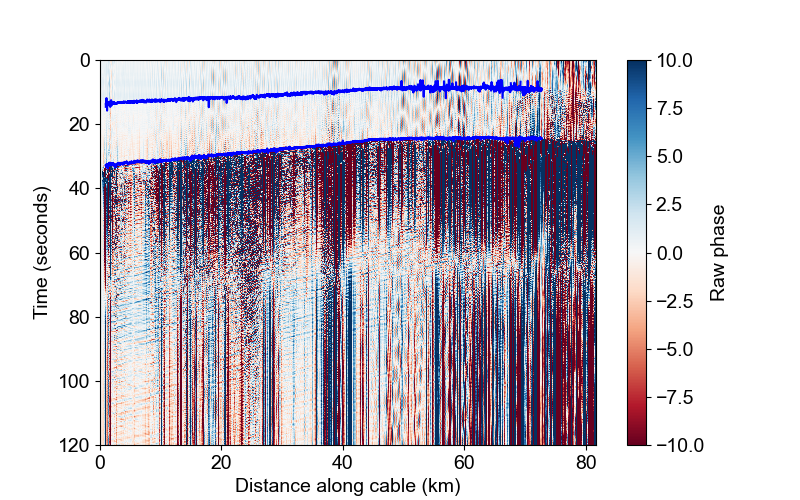

In [44]:
plt.figure(figsize=(8,5))
plt.imshow(kkfls_das, aspect='auto', cmap='RdBu',vmin=-10,vmax=10,extent=[kkfls_x_km[0],kkfls_x_km[-1],kkfls_t[-1],kkfls_t[0]])
plt.colorbar(label='Raw phase')
plt.ylabel('Time (seconds)')
plt.xlabel('Distance along cable (km)')

plt.plot([kkfls_x_km[i] for i in picks['channel']],picks['KKFLS_p_sec'],'b-')
plt.plot([kkfls_x_km[i] for i in picks['channel']],picks['KKFLS_s_sec'],'b-')

In [45]:
h5file = '20230728_M5_TERRA.h5'

data = h5py.File(h5file)
terra_attrs=dict(data['Acquisition'].attrs)
terra_das = np.array(data['Acquisition/Raw[0]/RawData'])
terra_time = np.array(data['Acquisition/Raw[0]/RawDataTime'])
data.close()

dt = 1/terra_attrs['MaximumFrequency']/2
dx = terra_attrs['SpatialSamplingInterval']
nt,nx = terra_das.shape

terra_x = np.linspace(0,nx*dx,nx) # This is in meters
terra_x_km = terra_x / 1000
terra_t = np.linspace(0,nt*dt,nt)

gl = terra_attrs['GaugeLength']
correction_factor = wavelength / (photoelastic_coefficient * 4 * np.pi * refractive_index * gl) # correction factor for strain rate
terra_corrected_das = terra_das * correction_factor

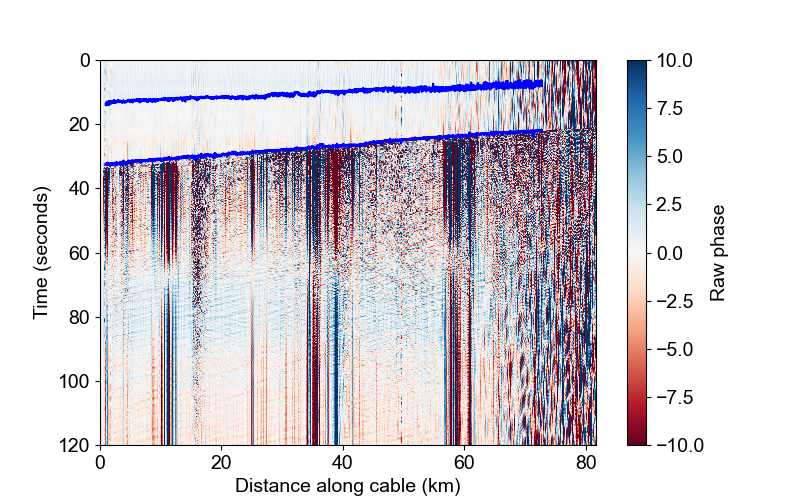

In [46]:
plt.figure(figsize=(8,5))
plt.imshow(terra_das, aspect='auto', cmap='RdBu',vmin=-10,vmax=10,extent=[terra_x_km[0],terra_x_km[-1],terra_t[-1],terra_t[0]])
plt.colorbar(label='Raw phase')
plt.ylabel('Time (seconds)')
plt.xlabel('Distance along cable (km)')

plt.plot([terra_x_km[i] for i in picks['channel']],picks['TERRA_p_sec'],'b-')
plt.plot([terra_x_km[i] for i in picks['channel']],picks['TERRA_s_sec'],'b-')

## Look at individual channels, downsample to 8 Hz

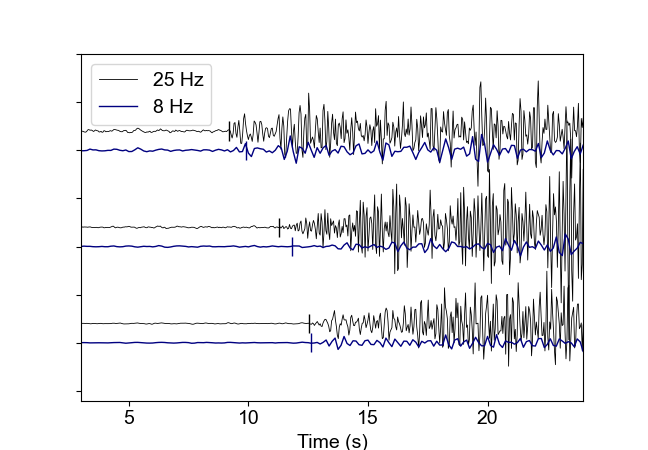

In [47]:
%matplotlib widget

fig,ax = plt.subplots(1,figsize=[6.48, 4.5 ])

count = 0
# for chan_ind in [700,1700,2700,3700,4700,5700]:
for chan_ind in [700,2700,4700]:
    pick_ind = chan_ind + 100
    
    chan = terra_corrected_das[:,chan_ind]
    
    p_pick_time = picks.iloc[pick_ind].TERRA_p_sec
    s_pick_time = picks.iloc[pick_ind].TERRA_s_sec
    fullrate_ind = [j for j in fullrate_picks.channel.to_list() if j==chan_ind][0]
    p_fullrate_time = fullrate_picks.iloc[fullrate_ind].pick_time_s
    ds_ind = [j for j in ds_picks.channel.to_list() if j==chan_ind][0]
    p_ds_time = ds_picks.iloc[ds_ind].pick_time_s
    
    
    # Downsample using same method as obspy
    data = chan
    tr = obspy.Trace(data=np.asarray(data, dtype=float).copy())
    tr.stats.sampling_rate = float(1/dt)
    
    tr2 = tr.copy()
    t1 = tr2.stats.starttime
    t2 = tr2.stats.endtime
    tr2.trim(t1-100,t2,fill_value=np.int32(np.mean(tr2.data[0:10])),pad=True) # pad ends so we can cut off edge effects
    tr2.trim(t1-100,t2+100,fill_value=np.int32(np.mean(tr2.data[-10:])),pad=True)

    tr2.filter('lowpass', freq=3, zerophase=True)
    tr2.resample(8.0,no_filter=True)
    tr2.trim(t1,t2) # cut off edge effects

    # tr = tr.detrend('demean')
    # tr2 = tr2.detrend('demean')

    tr.filter('highpass',freq = 1)
    tr2.filter('highpass',freq = 1)
    

    baseline = count * 5e-8

    if count==0:
        ax.plot(tr.times(),tr.data+ baseline+1e-8,'-',linewidth=0.6,color='k',label='25 Hz')
        ax.plot(tr2.times(),tr2.data+ baseline,'-',linewidth=1,color='navy',label='8 Hz')
    else:
        ax.plot(tr.times(),tr.data+ baseline+1e-8,'-',linewidth=0.6,color='k')
        ax.plot(tr2.times(),tr2.data+ baseline,'-',linewidth=1,color='navy')
    
    ax.vlines(p_fullrate_time,color='k',linewidth=1,ymin=baseline+1e-8 - (0.05e-7),ymax=baseline+1e-8 + (0.05e-7))
    ax.vlines(p_ds_time,color='navy',linewidth=1,ymin=baseline - (0.05e-7),ymax=baseline + (0.05e-7))
    
    # ax.axvline(s_pick_time,color='k',linewidth=1,linestyle='--')

    ax.set_xlim(3,24)
    ax.set_ylim(-10e-8,40e-8)

    count += 1

# ax.set_ylim(-0.3e-7,3.2e-7)
ax.set_ylim(-0.3e-7,1.5e-7)
ax.set_xlabel('Time (s)')
ax.set_yticklabels([])
ax.legend()

fig.patch.set_facecolor('none')  # Makes the outer figure background transparent
ax.patch.set_facecolor('white')  # Keeps the inner axes background solid white

plt.savefig('/Users/zoekrauss/shakealert_8hz/kona_figs/das_waveforms.png', dpi=300)

In [48]:
print(kkfls_dist[700])
print(kkfls_dist[2700])
print(kkfls_dist[4700])

151.13423648030277
132.70305673923195
115.09063273304994


## Downsample and make waterfall plot

In [49]:
# Bandpass filter between 2 and 10 Hz
b,a = butter(N=4, Wn=1, btype='highpass',fs=1/dt)
terra_filtered_das = filtfilt(b,a,terra_corrected_das,axis=0)

In [50]:
# Read Alex Roses' ELEP picks
fullrate_picks = pd.read_csv('elep_terra_p_uncertainty_TERRA_25Hz_ref_unc1_prob0.3.csv')
fullrate_picks = fullrate_picks[fullrate_picks['mean_max_prob'] >= 0.4]

In [51]:
fullrate_picks

,channel,mean_pick_time,std_pick_time,mean_max_prob,std_max_prob,combined_uncertainty,pick_time_s,std_pick_time_s,mean_pick_time_utc
8,62,340.25,2.277608,0.427599,0.046396,0.715501,13.610,0.091104,2023-07-28 19:11:47.890000+00:00
9,63,337.40,0.860233,0.506647,0.051267,0.616691,13.496,0.034409,2023-07-28 19:11:47.776000+00:00
10,64,336.80,1.029563,0.542828,0.050068,0.571465,13.472,0.041183,2023-07-28 19:11:47.752000+00:00
11,65,336.05,1.283550,0.591407,0.050842,0.510741,13.442,0.051342,2023-07-28 19:11:47.722000+00:00
12,66,334.90,0.943398,0.630535,0.046658,0.461831,13.396,0.037736,2023-07-28 19:11:47.676000+00:00
...,...,...,...,...,...,...,...,...,...
7376,7785,186.50,1.500000,0.401116,0.011386,0.748605,7.460,0.060000,2023-07-28 19:11:41.740000+00:00
7393,7802,189.00,0.000000,0.402255,0.016079,0.747182,7.560,0.000000,2023-07-28 19:11:41.840000+00:00
7394,7803,189.00,0.000000,0.412181,0.014824,0.734774,7.560,0.000000,2023-07-28 19:11:41.840000+00:00
7395,7804,189.00,0.000000,0.419905,0.014574,0.725119,7.560,0.000000,2023-07-28 19:11:41.840000+00:00


(0.0, 70.0)

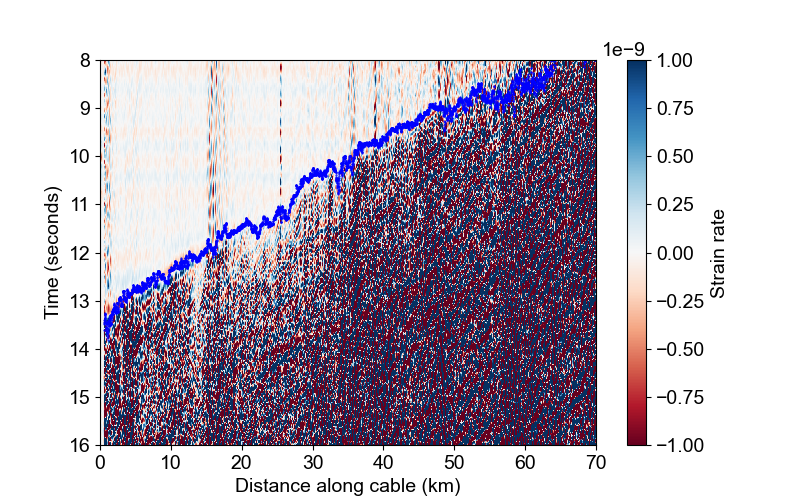

In [52]:
vmin = -0.1e-8
vmax = 0.1e-8

plt.figure(figsize=(8,5))
plt.imshow(terra_filtered_das, aspect='auto', cmap='RdBu',vmin=vmin,vmax=vmax,extent=[terra_x_km[0],terra_x_km[-1],terra_t[-1],terra_t[0]])
plt.colorbar(label='Strain rate')
plt.ylabel('Time (seconds)')
plt.xlabel('Distance along cable (km)')

plt.plot([terra_x_km[i] for i in fullrate_picks['channel']],fullrate_picks['pick_time_s'],'b.',markersize=1)

plt.ylim(16,8)
plt.xlim(0,70)

In [53]:
terra_downsampled_das = []

for chan_ind in range(np.shape(terra_corrected_das)[1]):

    chan = terra_corrected_das[:,chan_ind]
    
    # Downsample using same method as obspy
    data = chan
    tr = obspy.Trace(data=np.asarray(data, dtype=float).copy())
    tr.stats.sampling_rate = float(1/dt)
    
    tr2 = tr.copy()
    t1 = tr2.stats.starttime
    t2 = tr2.stats.endtime
    tr2.trim(t1-100,t2,fill_value=np.int32(np.mean(tr2.data[0:10])),pad=True) # pad ends so we can cut off edge effects
    tr2.trim(t1-100,t2+100,fill_value=np.int32(np.mean(tr2.data[-10:])),pad=True)
    
    tr2.resample(8.0,no_filter=False)
    tr2.trim(t1,t2) # cut off edge effects

    terra_downsampled_das.append(tr2.data)

terra_downsampled_t = tr2.times()
terra_downsampled_das = np.array(terra_downsampled_das).T

kkfls_downsampled_das = []
for chan_ind in range(np.shape(kkfls_corrected_das)[1]):

    chan = kkfls_corrected_das[:,chan_ind]
    
    # Downsample using same method as obspy
    data = chan
    tr = obspy.Trace(data=np.asarray(data, dtype=float).copy())
    tr.stats.sampling_rate = float(1/dt)
    
    tr2 = tr.copy()
    t1 = tr2.stats.starttime
    t2 = tr2.stats.endtime
    tr2.trim(t1-100,t2,fill_value=np.int32(np.mean(tr2.data[0:10])),pad=True) # pad ends so we can cut off edge effects
    tr2.trim(t1-100,t2+100,fill_value=np.int32(np.mean(tr2.data[-10:])),pad=True)

    tr2.filter('lowpass', freq=3.5, zerophase=True)
    tr2.resample(8.0,no_filter=True)
    # tr2.resample(8.0,no_filter=False)
    tr2.trim(t1,t2) # cut off edge effects

    kkfls_downsampled_das.append(tr2.data)

kkfls_downsampled_t = tr2.times()
kkfls_downsampled_das = np.array(kkfls_downsampled_das).T

In [54]:
# Bandpass filter between 2 and 10 Hz
b,a = butter(N=4, Wn=1, btype='highpass',fs=1/dt)
terra_filtered_downsampled_das = filtfilt(b,a,terra_downsampled_das,axis=0)

In [55]:
# Read Alex Roses' ELEP picks
ds_picks = pd.read_csv('elep_terra_p_uncertainty_TERRA_8Hz_unc1_prob0.3.csv')
ds_picks = ds_picks[ds_picks['mean_max_prob'] >= 0.4]

(0.0, 70.0)

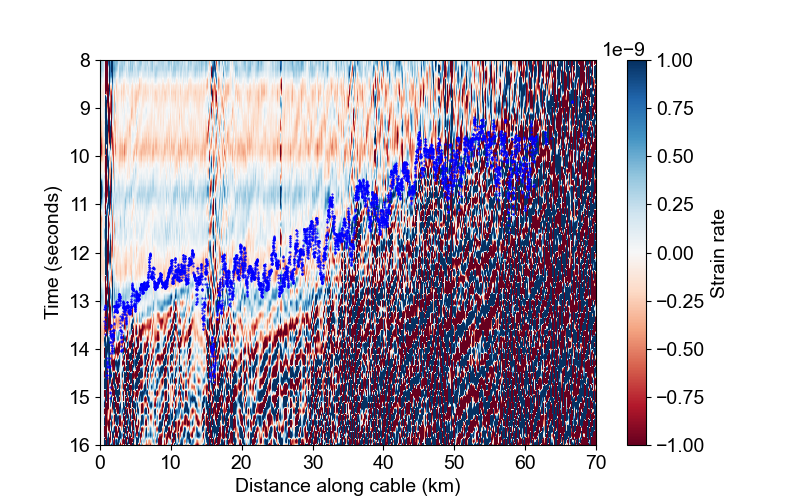

In [56]:
vmin = -0.1e-8
vmax = 0.1e-8


plt.figure(figsize=(8,5))
plt.imshow(terra_filtered_downsampled_das, aspect='auto', cmap='RdBu',vmin=vmin,vmax=vmax,extent=[terra_x_km[0],terra_x_km[-1],terra_downsampled_t[-1],terra_downsampled_t[0]])
plt.colorbar(label='Strain rate')
plt.ylabel('Time (seconds)')
plt.xlabel('Distance along cable (km)')

plt.plot([terra_x_km[i] for i in ds_picks['channel']],ds_picks['pick_time_s'],'b.',markersize=1)

plt.ylim(16,8)
plt.xlim(0,70)

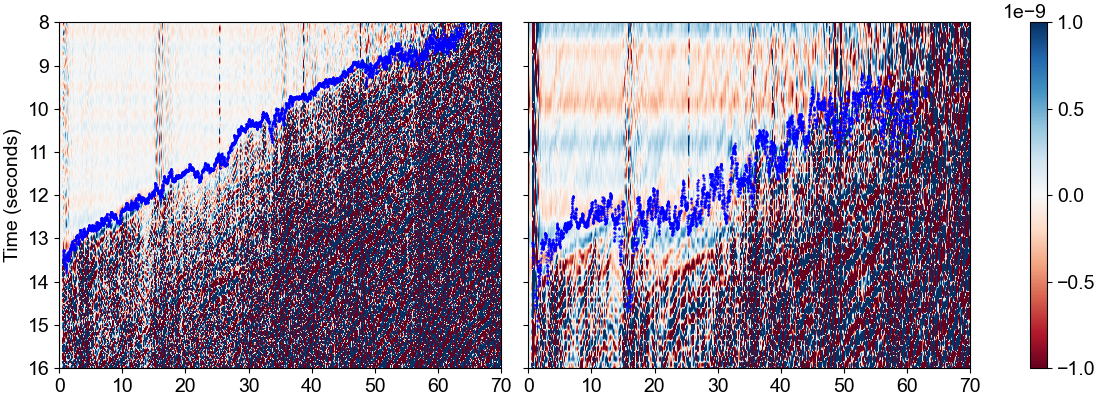

In [58]:
vmin = -0.1e-8
vmax = 0.1e-8

fig,ax = plt.subplots(1,2,constrained_layout=True,figsize=[11,4])
c = ax[0].imshow(terra_filtered_das, aspect='auto', cmap='RdBu',vmin=vmin,vmax=vmax,extent=[terra_x_km[0],terra_x_km[-1],terra_downsampled_t[-1],terra_downsampled_t[0]])
# ax[0].colorbar(label='Strain rate')
ax[0].plot([terra_x_km[i] for i in fullrate_picks['channel']],fullrate_picks['pick_time_s'],'b.',markersize=1)

ax[1].imshow(terra_filtered_downsampled_das, aspect='auto', cmap='RdBu',vmin=vmin,vmax=vmax,extent=[terra_x_km[0],terra_x_km[-1],terra_downsampled_t[-1],terra_downsampled_t[0]])
# ax[0].colorbar(label='Strain rate')
ax[1].plot([terra_x_km[i] for i in ds_picks['channel']],ds_picks['pick_time_s'],'b.',markersize=1)



ax[0].set_ylim(16,8)
ax[0].set_xlim(0,70)
ax[1].set_ylim(16,8)
ax[1].set_xlim(0,70)
ax[1].set_yticklabels([])

ax[0].set_ylabel('Time (seconds)')
fig.colorbar(c,ax=ax[1],ticks=[-1e-9,-0.5e-9,0,0.5e-9,1e-9])
# ax[0].set_xlabel('Distance along cable (km)')

fig.patch.set_facecolor('none')  # Makes the outer figure background transparent
ax[0].patch.set_facecolor('white')  # Keeps the inner axes background solid white
ax[1].patch.set_facecolor('white')  # Keeps the inner axes background solid white

plt.savefig('/Users/zoekrauss/shakealert_8hz/kona_figs/waterfalls.png', dpi=300)

In [27]:
plt.gcf().get_size_inches()

array([11.,  4.])

## Write to file for Alex

In [28]:
np.shape(terra_downsampled_das)

(961, 8531)

In [16]:
import pickle
with open('terra_downsampled_strainrate_20230728_M5.pkl', 'wb') as file:
    pickle.dump(terra_downsampled_das, file)

## Get cable locations

In [29]:
from geopy.distance import geodesic

In [30]:
terra_loc = pd.read_csv('TERRA_coords.xycz',sep='\t',names=['lon','lat','chan','elev'])
kkfls_loc = pd.read_csv('KKFLS_coords.xycz',sep='\t',names=['lon','lat','chan','elev'])

# Get distance from eq
EVENT_LAT = 59.004
EVENT_LON = -153.977

terra_dist = []
for i in range(len(terra_loc)):
    if np.isnan(terra_loc.iloc[i].lon):
        terra_dist.append(np.nan)
    else:
        terra_dist.append(geodesic((EVENT_LAT,EVENT_LON),(terra_loc.iloc[i].lat,terra_loc.iloc[i].lon)).km)

kkfls_dist = []
for i in range(len(kkfls_loc)):
    if np.isnan(kkfls_loc.iloc[i].lon):
        kkfls_dist.append(np.nan)
    else:
        kkfls_dist.append(geodesic((EVENT_LAT,EVENT_LON),(kkfls_loc.iloc[i].lat,kkfls_loc.iloc[i].lon)).km)

## Get amplitude diminishing info - P waves

In [31]:
## Get amplitudes of P-waves

terra_orig_p_amps = []
terra_ds_p_amps = []
terra_dist = []
for i in range(len(picks)):

    chan_ind = i + 100

    pick_time = picks.iloc[i].TERRA_p_sec

    if ~np.isnan(pick_time):

        check_ind = [j for j,v in enumerate(terra_t) if (v > pick_time) & (v < pick_time+2)]
        check_vals = [terra_corrected_das[j,chan_ind] for j in check_ind]
        terra_orig_p_amps.append(np.max(np.abs(check_vals)))

        check_ind = [j for j,v in enumerate(terra_downsampled_t) if (v > pick_time) & (v < pick_time+2)]
        check_vals = [terra_downsampled_das[j,chan_ind] for j in check_ind]
        terra_ds_p_amps.append(np.max(np.abs(check_vals)))

        chan_lat = terra_loc.iloc[chan_ind].lat
        chan_lon = terra_loc.iloc[chan_ind].lon
        terra_dist.append(geodesic((EVENT_LAT,EVENT_LON),(chan_lat,chan_lon)).km)

    else:
        terra_orig_p_amps.append(np.nan)
        terra_ds_p_amps.append(np.nan)
        terra_dist.append(np.nan)

kkfls_orig_p_amps = []
kkfls_ds_p_amps = []
kkfls_dist = []
for i in range(len(picks)):

    chan_ind = i + 100

    pick_time = picks.iloc[i].KKFLS_p_sec

    if ~np.isnan(pick_time):

        check_ind = [j for j,v in enumerate(kkfls_t) if (v > pick_time) & (v < pick_time+2)]
        check_vals = [kkfls_corrected_das[j,chan_ind] for j in check_ind]
        kkfls_orig_p_amps.append(np.max(np.abs(check_vals)))

        check_ind = [j for j,v in enumerate(kkfls_downsampled_t) if (v > pick_time) & (v < pick_time+2)]
        check_vals = [kkfls_downsampled_das[j,chan_ind] for j in check_ind]
        kkfls_ds_p_amps.append(np.max(np.abs(check_vals)))

        chan_lat = kkfls_loc.iloc[chan_ind].lat
        chan_lon = kkfls_loc.iloc[chan_ind].lon
        if ~np.isnan(chan_lat):
            kkfls_dist.append(geodesic((EVENT_LAT,EVENT_LON),(chan_lat,chan_lon)).km)
        else:
            kkfls_dist.append(np.nan)


    else:
        kkfls_orig_p_amps.append(np.nan)
        kkfls_ds_p_amps.append(np.nan)
        kkfls_dist.append(np.nan)

In [32]:
terra_dist_p = terra_dist
kkfls_dist_p = kkfls_dist

In [33]:
## Get amplitudes of S-waves

orig_s_amps = []
ds_s_amps = []
for i in range(len(picks)):

    chan_ind = i + 100

    pick_time = picks.iloc[i].TERRA_s_sec

    if ~np.isnan(pick_time):

        check_ind = [j for j,v in enumerate(terra_t) if (v > pick_time) & (v < pick_time+3)]
        check_vals = [terra_corrected_das[j,chan_ind] for j in check_ind]
        orig_s_amps.append(np.max(np.abs(check_vals)))

        check_ind = [j for j,v in enumerate(terra_downsampled_t) if (v > pick_time) & (v < pick_time+3)]
        check_vals = [terra_downsampled_das[j,chan_ind] for j in check_ind]
        ds_s_amps.append(np.max(np.abs(check_vals)))

Text(0.5, 0, 'Distance from eq (km)')

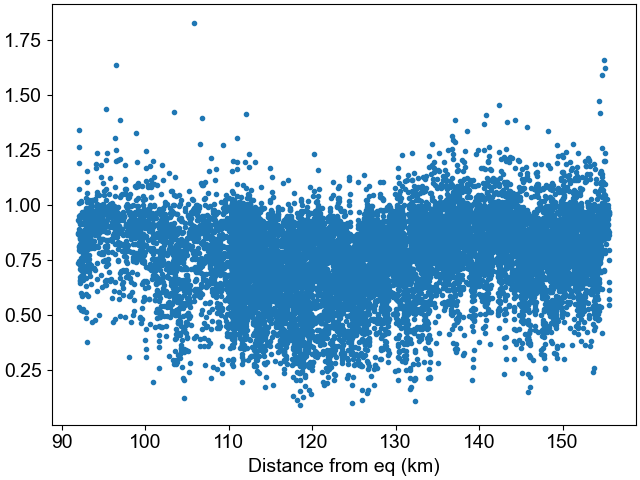

In [34]:
fig,ax = plt.subplots(1,constrained_layout=True)

terra_p_ratio = np.array(terra_ds_p_amps)/np.array(terra_orig_p_amps)
kkfls_p_ratio = np.array(kkfls_ds_p_amps)/np.array(kkfls_orig_p_amps)
ax.plot(terra_dist,terra_p_ratio,'.',color='tab:blue')
ax.plot(kkfls_dist,kkfls_p_ratio,'.')

ax.set_xlabel('Distance from eq (km)')

## Amplitude diminishing info - overall motion

In [35]:
orig_amps = np.max(np.abs(terra_corrected_das),axis=0)
downsampled_amps = np.max(np.abs(terra_downsampled_das),axis=0)
terra_amps_ratio = downsampled_amps/orig_amps

orig_amps = np.max(np.abs(kkfls_corrected_das),axis=0)
downsampled_amps = np.max(np.abs(kkfls_downsampled_das),axis=0)
kkfls_amps_ratio = downsampled_amps/orig_amps

In [36]:
terra_loc = pd.read_csv('TERRA_coords.xycz',sep='\t',names=['lon','lat','chan','elev'])
kkfls_loc = pd.read_csv('KKFLS_coords.xycz',sep='\t',names=['lon','lat','chan','elev'])

# Get distance from eq
EVENT_LAT = 59.004
EVENT_LON = -153.977

terra_dist = []
for i in range(len(terra_loc)):
    if np.isnan(terra_loc.iloc[i].lon):
        terra_dist.append(np.nan)
    else:
        terra_dist.append(geodesic((EVENT_LAT,EVENT_LON),(terra_loc.iloc[i].lat,terra_loc.iloc[i].lon)).km)

kkfls_dist = []
for i in range(len(kkfls_loc)):
    if np.isnan(kkfls_loc.iloc[i].lon):
        kkfls_dist.append(np.nan)
    else:
        kkfls_dist.append(geodesic((EVENT_LAT,EVENT_LON),(kkfls_loc.iloc[i].lat,kkfls_loc.iloc[i].lon)).km)

In [37]:
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 

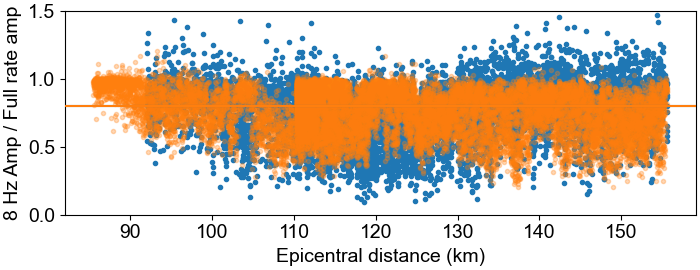

In [38]:
fig,ax = plt.subplots(1,figsize=[7,2.7],constrained_layout = True)

ax.plot(terra_dist_p,terra_p_ratio,'.',color='tab:blue')
ax.plot(kkfls_dist_p,kkfls_p_ratio,'.',color='tab:blue')
p_ratio_median = np.nanmedian([terra_p_ratio,kkfls_p_ratio])
ax.axhline(p_ratio_median,color='tab:blue',zorder=10)

ax.plot(terra_dist,terra_amps_ratio,'.',color='tab:orange',alpha=0.3)
ax.plot(kkfls_dist,kkfls_amps_ratio,'.',color='tab:orange',alpha=0.3)
all_ratio_median = np.nanmedian([terra_amps_ratio,kkfls_amps_ratio])
ax.axhline(all_ratio_median,color='tab:orange',zorder=10)

ax.set_xlabel('Epicentral distance (km)')
ax.set_ylabel('8 Hz Amp / Full rate amp')
ax.set_ylim(0,1.5)

fig.patch.set_facecolor('none')  # Makes the outer figure background transparent
ax.patch.set_facecolor('white')  # Keeps the inner axes background solid white


plt.savefig('/Users/zoekrauss/shakealert_8hz/kona_figs/alaska_das_amplitude_scatter.png', dpi=300)

In [112]:
plt.gcf().get_size_inches()

array([7. , 2.7])

In [27]:
np.nanmedian([terra_p_ratio,kkfls_p_ratio])

0.8006649556187302

In [28]:
np.nanmedian(terra_amps_ratio)

0.7218001228509578

In [242]:
np.mean(amps_ratio)

0.7161155767109925

In [243]:
M = 5
10**(0.437 * M)

153.10874616820303

In [263]:
np.log10(153 * 0.75) * (1/0.437)

4.713392892927458